# Domain and orography

Orography of CRCM6-GEM5, ERA5 and the three driving AOGCMs, each on its native grid, with the CRCM6-GEM5 domain
and, on the CRCM6-GEM5 panel, the NNA region of Sect. 3.3 (land cells of CRCM6-GEM5 between 40 and 50N and between 90 and 60W, as in
`REGION_BOXES['NNA2']` of `POSTPROCESSING/storm_percentile_metrics.py`).

Sources, in `ALL/OROG/` (and `ALL/MASK/` for the CRCM6 and ERA5 land-sea masks):
- CRCM6-GEM5: `CRCM6_orog.nc` (same orography for all simulations, pilot zone removed);
- ERA5: surface geopotential from the Copernicus Climate Data Store, divided by g;
- AOGCMs: CMIP6 `orog` and `sftlf` (table fx, historical) from ESGF; the orography does not depend on the member.

In [1]:
import glob
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [2]:
base = '/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL'

# CRCM6 rotated pole, used as map projection
MAP_PROJ = ccrs.RotatedPole(pole_longitude=83., pole_latitude=42.5)

# Orography (m) and land mask (land fraction >= 50 %) of each dataset, on its native grid
orog, land = {}, {}

orog['CRCM6-GEM5'] = xr.open_dataset(f'{base}/OROG/CRCM6_orog.nc').orog
land['CRCM6-GEM5'] = xr.open_dataset(f'{base}/MASK/CRCM6_lsmsk.nc4').sftlf.squeeze(drop=True) >= 50

z = xr.open_dataset(f'{base}/OROG/ERA5_geopotential_surface.nc').z.squeeze(drop=True)
lsm = xr.open_dataset(f'{base}/MASK/ERA5_lsm.nc').lsm.squeeze(drop=True)
lsm = lsm.assign_coords(longitude=lsm.longitude % 360).sortby('longitude').reindex_like(z, method='nearest', tolerance=1e-3)
orog['ERA5'] = (z / 9.80665).rename(latitude='lat', longitude='lon')
land['ERA5'] = (lsm >= 0.5).rename(latitude='lat', longitude='lon')

for model in ['EC-Earth3-Veg', 'MPI-ESM1-2-HR', 'MIROC6']:
    orog[model] = xr.open_dataset(glob.glob(f'{base}/OROG/orog_fx_{model}_*.nc')[0]).orog
    land[model] = xr.open_dataset(glob.glob(f'{base}/OROG/sftlf_fx_{model}_*.nc')[0]).sftlf >= 50

# NNA region of Sect. 3.3, as in storm_percentile_metrics.py (REGION_BOXES['NNA2'], land mask 'land'): CRCM6-GEM5
# grid cells with a land fraction > 0 inside the lon-lat box
NNA_BOX = {'west_lon': -90.0, 'east_lon': -60.0, 'south_lat': 40.0, 'north_lat': 50.0}
grid = orog['CRCM6-GEM5']
nna = ((xr.open_dataset(f'{base}/MASK/CRCM6_lsmsk.nc4').sftlf.squeeze(drop=True) > 0)
       & (grid.lon >= NNA_BOX['west_lon']) & (grid.lon <= NNA_BOX['east_lon'])
       & (grid.lat >= NNA_BOX['south_lat']) & (grid.lat <= NNA_BOX['north_lat']))
print(f'NNA region: {int(nna.sum())} CRCM6-GEM5 grid cells')
NNA_COLOR = '#d7191c'

# Panel titles: native grid of each dataset
titles = {
    'CRCM6-GEM5': 'CRCM6-GEM5 (0.11°)',
    'ERA5': 'ERA5 (0.25°)',
    'EC-Earth3-Veg': 'EC-Earth3-Veg (T255, 0.70°)',
    'MPI-ESM1-2-HR': 'MPI-ESM1-2-HR (T127, 0.94°)',
    'MIROC6': 'MIROC6 (T85, 1.4°)',
}

NNA region: 12406 CRCM6-GEM5 grid cells


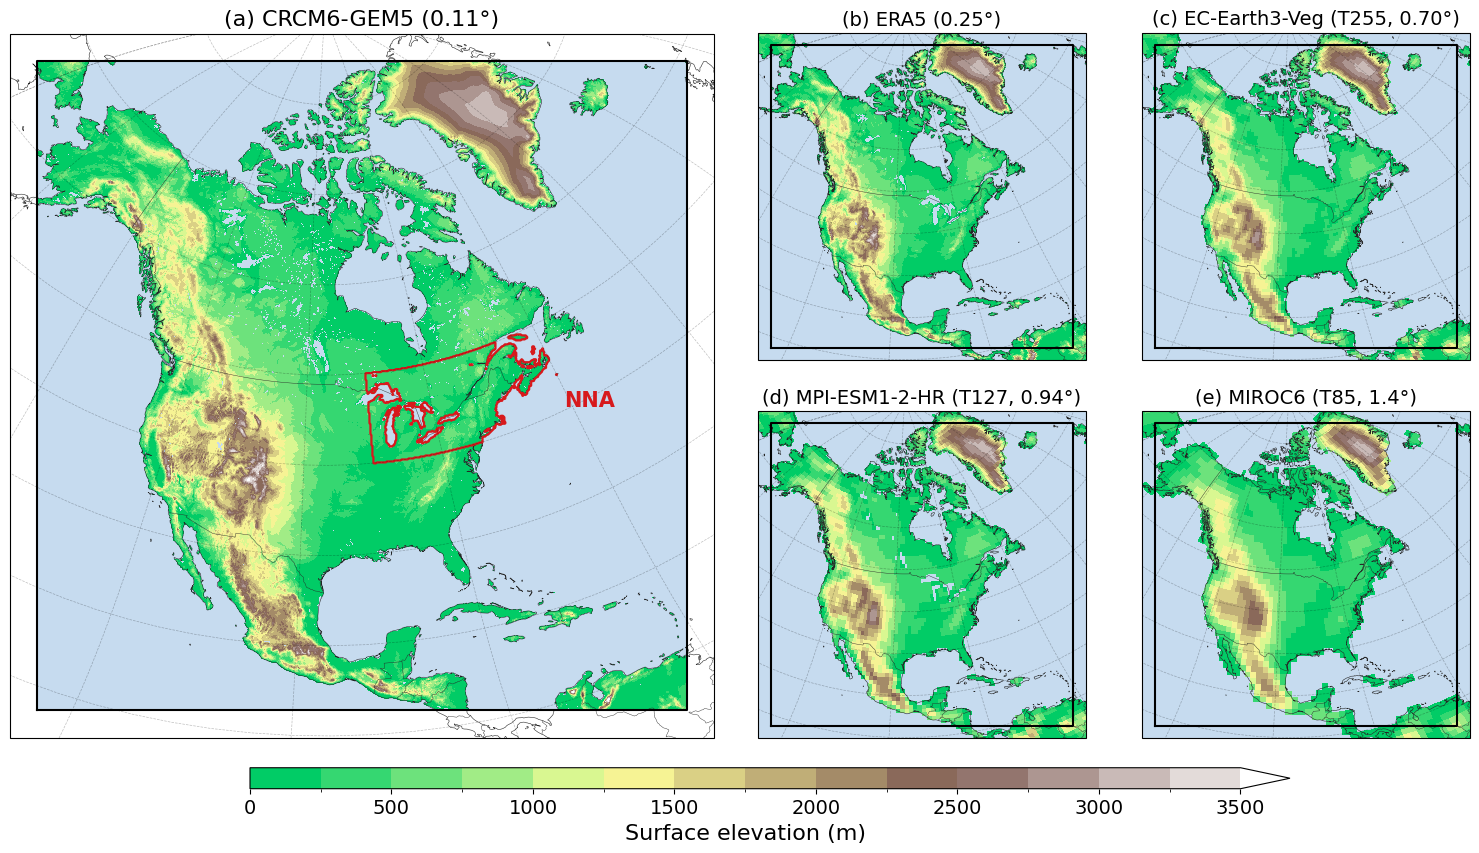

In [3]:
def edges(c):
    """Cell edges from the cell centres of a 1-D coordinate."""
    mid = (c[1:] + c[:-1]) / 2
    return np.concatenate([[2 * c[0] - mid[0]], mid, [2 * c[-1] - mid[-1]]])

def on_map(da):
    """Cell edges in map coordinates and values of a field, over the CRCM6 domain."""
    if 'rlon' in da.dims:
        return edges(da.rlon.values), edges(da.rlat.values), da.values
    # Global lat-lon grids: longitudes from 150 to 390 degrees, since the domain extends
    # from 174E to 3W, across the 0/360 seam of the grids
    da = da.sortby('lat').sel(lat=slice(-10, 90))
    da = xr.concat([da, da.assign_coords(lon=da.lon + 360)], 'lon').sel(lon=slice(150, 390))
    lon_e, lat_e = np.meshgrid(edges(da.lon.values), np.clip(edges(da.lat.values), -90, 90))
    xyz = MAP_PROJ.transform_points(ccrs.PlateCarree(), lon_e, lat_e)
    return xyz[..., 0], xyz[..., 1], da.values

# CRCM6 domain in rotated coordinates
rlon_e, rlat_e = edges(orog['CRCM6-GEM5'].rlon.values), edges(orog['CRCM6-GEM5'].rlat.values)
x0, x1, y0, y1 = rlon_e[0], rlon_e[-1], rlat_e[0], rlat_e[-1]
margin = 3.

levels = np.arange(0, 3750, 250)
# Land part of 'terrain' (green lowlands, brown mountains)
cmap = mcolors.LinearSegmentedColormap.from_list('terrain_land', plt.get_cmap('terrain')(np.linspace(0.25, 1, 256)))
norm = mcolors.BoundaryNorm(levels, cmap.N, extend='max')
ocean = mcolors.ListedColormap(['#c6dbef'])

fig = plt.figure(figsize=(16, 8.4))
positions = {
    'CRCM6-GEM5': [0.00, 0.10, 0.44, 0.84],
    'ERA5': [0.46, 0.55, 0.22, 0.39],
    'EC-Earth3-Veg': [0.70, 0.55, 0.22, 0.39],
    'MPI-ESM1-2-HR': [0.46, 0.10, 0.22, 0.39],
    'MIROC6': [0.70, 0.10, 0.22, 0.39],
}

for letter, (name, pos) in zip('abcde', positions.items()):
    ax = fig.add_axes(pos, projection=MAP_PROJ)
    ax.set_extent([x0 - margin, x1 + margin, y0 - margin, y1 + margin], crs=MAP_PROJ)

    x, y, h = on_map(orog[name])
    _, _, is_land = on_map(land[name])
    ax.pcolormesh(x, y, np.where(is_land, np.nan, 1.), cmap=ocean, shading='flat', rasterized=True)
    sc = ax.pcolormesh(x, y, np.where(is_land, h, np.nan), cmap=cmap, norm=norm, shading='flat', rasterized=True)

    ax.coastlines(resolution='50m', linewidth=0.4, color='0.15')
    ax.add_feature(cfeature.BORDERS.with_scale('50m'), linewidth=0.3, edgecolor='0.15')
    ax.gridlines(linewidth=0.5, linestyle='--', color='k', alpha=0.25, xlocs=range(-180, 181, 20), ylocs=range(0, 91, 10))
    # CRCM6 domain
    ax.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], color='k', linewidth=1.5)
    # NNA region (Sect. 3.3): outline of its grid cells, on the CRCM6-GEM5 panel only
    if name == 'CRCM6-GEM5':
        ax.contour(nna.rlon, nna.rlat, nna.astype(float), levels=[0.5], colors=NNA_COLOR, linewidths=1.6)
        rlon_nna = nna.rlon.where(nna.any('rlat'), drop=True)
        rlat_nna = nna.rlat.where(nna.any('rlon'), drop=True)
        ax.text(float(rlon_nna.max()) + 0.8, float(rlat_nna.mean()), 'NNA', color=NNA_COLOR, fontsize=15,
                fontweight='bold', ha='left', va='center')
    ax.set_title(f'({letter}) {titles[name]}', fontsize=16 if name == 'CRCM6-GEM5' else 14)

cbar_ax = fig.add_axes([0.15, 0.04, 0.65, 0.025])
cbar = fig.colorbar(sc, cax=cbar_ax, orientation='horizontal', extend='max', ticks=levels[::2])
cbar.set_label('Surface elevation (m)', fontsize=16)
cbar.ax.tick_params(labelsize=14)

plt.savefig(f'{base}/PLOT/orography_domain.png', dpi=300, bbox_inches='tight')
plt.show()